In [1]:
import numpy as np
import pandas as pd
import os
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [2]:
def load_csv(file_path):
    """Loads a CSV file into a DataFrame"""
    try:
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Error: File '{file_path}' not found!")

        df = pd.read_csv(file_path)

        print(f"✅ CSV file! Shape: {df.shape}")

        return df
    except FileNotFoundError as fnf_error:
        print(fnf_error)
    except pd.errors.EmptyDataError:
        print("Error: The CSV file is empty!")
    except pd.errors.ParserError:
        print("Error: CSV parsing issue. Check the file format.")
    except Exception as e:
        print(f"Unexpected error: {e}")

    return None  

In [3]:
df = pd.read_csv('/kaggle/input/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')

# Quick peek on data

In [4]:
# df.head()

In [5]:
# df.columns

In [6]:

# def get_basic_info(df):
#     """Get basic information about the dataset"""
#     print(f"🔹 Number of Rows: {df.shape[0]}")
#     print(f"🔹 Number of Columns: {df.shape[1]}")
#     print(f"🔹 Columns: {df.columns.tolist()}")
#     print(f"🔹 Column Data Types: {df.dtypes}")
#     print(f"🔹 Missing Values: {df.isnull().sum().sum()}")
#     print(f"🔹 Missing Values (Per Column) : {df.isnull().sum()}")
#     print(f"🔹 Missing Values (Per Column Percentage) : {(df.isnull().mean() * 100)}")
#     print(f"🔹 Unique Values: {df.nunique()}")

In [7]:
# get_basic_info(df)

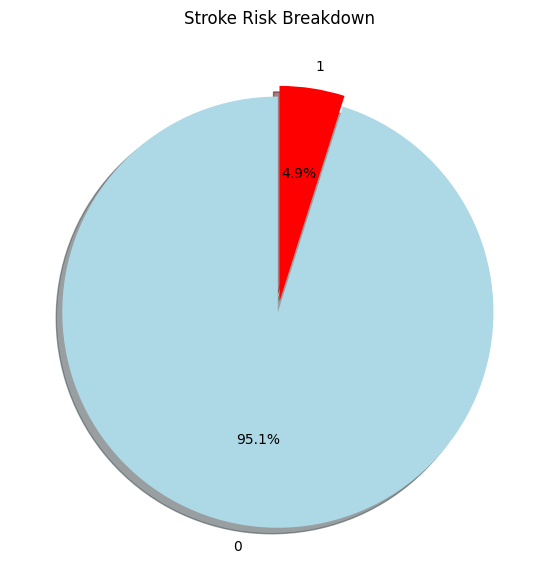

In [8]:
labels = df['stroke'].value_counts(sort=True).index
sizes = df['stroke'].value_counts(sort=True)

colors = ["lightblue", "red"]
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes[:2], explode=explode, labels=labels[:2], colors=colors, autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Stroke Risk Breakdown')
plt.show()

# Preprocessing Steps

In [9]:
# Check for class imbalance
df['stroke'].value_counts()/len(df)

stroke
0    0.951272
1    0.048728
Name: count, dtype: float64

In [10]:
# Check for duplicates  --> ~0.015%
print("Duplicates:", df.duplicated().sum()/len(df))
df.drop_duplicates(inplace=True)

Duplicates: 0.0


In [11]:
df.drop('id',axis=1,inplace=True) 

In [12]:
# df.info()

# 3. Handling Missing Values

In [13]:
# Missing values  --> no missing values
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [14]:
def plot_missing_heatmap(df):
    """Plot a heatmap to visualize missing values in the dataset."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(df.isnull(), cmap="viridis", cbar=False, yticklabels=False)
    plt.title("Missing Data Heatmap")
    plt.show()

In [15]:
def plot_missing_bar(df):
    """Plot a bar chart showing the count of missing values per column."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_values.index, y=missing_values.values, palette="magma")
    plt.xticks(rotation=90)
    plt.title("Missing Values Count per Column")
    plt.ylabel("Count")
    plt.show()

In [16]:
def plot_missing_pie(df):
    """Plot a pie chart showing the percentage of missing values per column."""
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if missing_percent.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(8, 8))
    plt.pie(missing_percent, labels=missing_percent.index, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title("Percentage of Missing Values per Column")
    plt.show()

In [17]:
# plot_missing_heatmap(df)

In [18]:
# plot_missing_bar(df)

In [19]:
# plot_missing_pie(df)

In [20]:
df.head(3)

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1


In [21]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

# Dealing with all the numerical features(nulls/scailing)

In [22]:
numerical = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical

['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

In [23]:
# plt.figure(figsize=(10,6))
# sns.histplot(df.age,kde=True,bins=30)

In [24]:
df.age[df.age < 1].value_counts()

age
0.88    5
0.32    5
0.24    5
0.56    5
0.72    5
0.64    4
0.80    4
0.16    3
0.48    3
0.40    2
0.08    2
Name: count, dtype: int64

# Is that a mistake let's check

In [25]:
df[df.age < 1]

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
363,Female,0.64,0,0,No,children,Urban,83.82,24.9,Unknown,0
376,Female,0.88,0,0,No,children,Rural,88.11,15.5,Unknown,0
564,Female,0.32,0,0,No,children,Rural,73.71,16.2,Unknown,0
982,Male,0.88,0,0,No,children,Rural,157.57,19.2,Unknown,0
996,Male,0.24,0,0,No,children,Rural,118.87,16.3,Unknown,0
1093,Female,0.32,0,0,No,children,Rural,55.86,16.0,Unknown,0
1206,Female,0.72,0,0,No,children,Urban,66.36,23.0,Unknown,0
1317,Male,0.80,0,0,No,children,Rural,98.67,17.5,Unknown,0
1600,Male,0.40,0,0,No,children,Urban,109.56,14.3,Unknown,0
1614,Female,0.08,0,0,No,children,Urban,139.67,14.1,Unknown,0


In [26]:
df.work_type[df.age < 1] == 'children'

363     True
376     True
564     True
982     True
996     True
1093    True
1206    True
1317    True
1600    True
1614    True
1808    True
1975    True
1999    True
2008    True
2012    True
2030    True
2358    True
2481    True
2490    True
2579    True
2630    True
2801    True
2875    True
2898    True
3251    True
3295    True
3392    True
3440    True
3618    True
3626    True
3859    True
3894    True
3968    True
4007    True
4021    True
4053    True
4293    True
4409    True
4581    True
4645    True
4910    True
4929    True
5089    True
Name: work_type, dtype: bool

It appears that it's not a mistake these are children(infants)

In [27]:
df.hypertension.value_counts()

hypertension
0    4612
1     498
Name: count, dtype: int64

In [28]:
# plt.figure(figsize=(10,6))
# plt.pie(df.hypertension.value_counts(),labels=['No Hypertension','Hypertension'],autopct='%1.1f%%',
#         colors=sns.color_palette('mako',2),explode=(0.3,0.1),shadow=True,textprops={'fontsize':12,'style':'italic'})

In [29]:
# df.heart_disease.value_counts()

In [30]:
# plt.figure(figsize=(10,6))
# plt.pie(df.heart_disease.value_counts(),labels=['No Heart disease','Heart disease'],autopct='%1.1f%%',
#         colors=sns.color_palette('mako',2),explode=(0.3,0.1),shadow=True,textprops={'fontsize':12,'style':'italic'})

In [31]:
# plt.figure(figsize=(10,6))
# sns.histplot(df.avg_glucose_level,kde=True,bins=30)

In [32]:
# df.avg_glucose_level.describe()

In [33]:
# plt.figure(figsize=(10,6))
# sns.histplot(df.bmi,kde=True,bins=30)

In [34]:
df.bmi.describe()

count    4909.000000
mean       28.893237
std         7.854067
min        10.300000
25%        23.500000
50%        28.100000
75%        33.100000
max        97.600000
Name: bmi, dtype: float64

***Dealing with the nulls***# 

In [35]:
df.bmi.fillna(df.bmi.mean(),inplace=True)

/tmp/ipykernel_107/799814321.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.bmi.fillna(df.bmi.mean(),inplace=True)


In [36]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

# *Dealing with all the categorical features(nulls (if exists)/encoding)*

In [37]:
categories = df.select_dtypes(include=['object']).columns.tolist()
categories

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [38]:
df.gender.value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

***Dropping the Other as it should be female or male***

In [39]:
df.drop(df[df.gender == 'Other'].index,inplace=True)
df.reset_index(drop=True,inplace=True)

In [40]:
# plt.figure(figsize=(10,6))
# sns.countplot(x="gender", data=df, palette='mako',hue='stroke')
# plt.legend(['no stroke','stroke'])


***Mapping the gender***

In [41]:
df.gender = df.gender.map({'Male':0,'Female':1})

In [42]:
df.ever_married.value_counts()

ever_married
Yes    3353
No     1756
Name: count, dtype: int64

In [43]:
# plt.figure(figsize=(10,6))
# sns.countplot(x="ever_married", data=df, palette='mako',hue='stroke')
# plt.legend(['no stroke','stroke'])

***Mapping the ever_married***

In [44]:
df.ever_married = df.ever_married.map({'No':0,'Yes':1})

In [45]:
df.work_type.value_counts()

work_type
Private          2924
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

In [46]:
# plt.figure(figsize=(10,6))
# sns.countplot(x="work_type", data=df, palette='mako',hue='stroke')
# plt.legend(['no stroke','stroke'])

***Mapping the work_type***

In [47]:
df.work_type = df.work_type.map({'Private':0,'Self-employed':1,'children':2,'Govt_job':3,'Never_worked':4})

In [48]:
df.Residence_type.value_counts()

Residence_type
Urban    2596
Rural    2513
Name: count, dtype: int64

In [49]:
# plt.figure(figsize=(10,6))
# sns.countplot(x="Residence_type", data=df, palette='mako',hue='stroke')
# plt.legend(['no stroke','stroke'])

***Mapping the Residence_type***

In [50]:
df.Residence_type = df.Residence_type.map({'Urban':0,'Rural':1})

In [51]:
df.smoking_status.value_counts()

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     884
smokes              789
Name: count, dtype: int64

In [52]:
# plt.figure(figsize=(10,6))
# sns.countplot(x="smoking_status", data=df, palette='mako',hue='stroke')
# plt.legend(['no stroke','stroke'])

***Mapping the smoking_status***

In [53]:
df.smoking_status = df.smoking_status.map({'never smoked':0,'formerly smoked':1,'smokes':2,'Unknown':3})

In [54]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1


In [55]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [56]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean': 
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")
            
    return df

In [57]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)  
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")
            
    return df

In [58]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")
                
    return df

In [59]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """
    
    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df
    
    return df_imputed

In [60]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [61]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []
    
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']: 
            if df[col].nunique() == 2:  
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':  
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [62]:
# df.head(10)

In [63]:
classify_columns(df)

{'binary': ['gender',
  'hypertension',
  'heart_disease',
  'ever_married',
  'Residence_type',
  'stroke'],
 'numerical': ['age',
  'work_type',
  'avg_glucose_level',
  'bmi',
  'smoking_status'],
 'categorical': []}

In [64]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()
    
    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold: 
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")
    
    return filtered_classification

In [65]:
column_classification = {
    'binary': ['gender',
  'hypertension',
  'heart_disease',
  'ever_married',
  'Residence_type',
  'stroke'],
 'numerical': ['age',
  'work_type',
  'avg_glucose_level',
  'bmi',
  'smoking_status'],
 'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['gender', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'stroke'], 'numerical': ['age', 'work_type', 'avg_glucose_level', 'bmi', 'smoking_status'], 'categorical': []}


In [66]:
# df.head()
# df.isnull().sum()


In [67]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'gender' with mode: 1
🔹 Imputed missing values in binary column 'hypertension' with mode: 0
🔹 Imputed missing values in binary column 'heart_disease' with mode: 0
🔹 Imputed missing values in binary column 'ever_married' with mode: 1
🔹 Imputed missing values in binary column 'Residence_type' with mode: 0
🔹 Imputed missing values in binary column 'stroke' with mode: 0


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...
5104,1,80.0,1,0,1,0,0,83.75,28.893237,0,0
5105,1,81.0,0,0,1,1,0,125.20,40.000000,0,0
5106,1,35.0,0,0,1,1,1,82.99,30.600000,0,0
5107,0,51.0,0,0,1,0,1,166.29,25.600000,1,0


In [68]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'age' with most frequent: 78.0
🔹 Imputed missing values in numerical column 'work_type' with most frequent: 0
🔹 Imputed missing values in numerical column 'avg_glucose_level' with most frequent: 93.88
🔹 Imputed missing values in numerical column 'bmi' with most frequent: 28.893236911794666
🔹 Imputed missing values in numerical column 'smoking_status' with most frequent: 0


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,0,0,228.69,36.600000,1,1
1,1,61.0,0,0,1,1,1,202.21,28.893237,0,1
2,0,80.0,0,1,1,0,1,105.92,32.500000,0,1
3,1,49.0,0,0,1,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,1,1,1,174.12,24.000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...
5104,1,80.0,1,0,1,0,0,83.75,28.893237,0,0
5105,1,81.0,0,0,1,1,0,125.20,40.000000,0,0
5106,1,35.0,0,0,1,1,1,82.99,30.600000,0,0
5107,0,51.0,0,0,1,0,1,166.29,25.600000,1,0


In [69]:
# # Plot Histogram to See the Distribution of the Data

# fig = plt.figure(figsize = (15,20))
# ax = fig.gca()
# df.hist(ax = ax)
# plt.show()

Only stroke Partipants¶

In [70]:
# # Plot Histogram to See the Distribution of the Data for Heart Disease Cases
# dataset_copy=df[df['stroke']==1]
# columns=df.columns[:21]
# fig = plt.figure(figsize = (15,20))
# ax = fig.gca()
# dataset_copy.hist(ax = ax)
# plt.show()

histogram

In [71]:
def plot_binary_distribution(df, binary_cols):
    """Plot count plots for binary features to visualize the distribution of 0s and 1s."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='Set2', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    # Hide any extra subplots
    for i in range(num_plots, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


boxplot

In [72]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distribution."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for i in range(num_plots, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


plot_kde

In [73]:
def plot_kde(df, numerical_cols):
    """Plot KDE (Kernel Density Estimate) for numerical features to visualize smooth distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
        axes[i].set_title(f"KDE of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Density")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

In [74]:
# plot_binary_distribution(df, filtered_classification["binary"])


In [75]:
# plot_binary_countplots(df, filtered_classification["binary"])


In [76]:
# plot_kde(df, filtered_classification["numerical"])

In [77]:
def plot_barplot(df, categorical_cols):
    """Plot bar plots for categorical features to visualize the distribution of different categories."""
    num_plots = len(categorical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0) 
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(categorical_cols):
        sns.countplot(x=df[col], palette="Set2", ax=axes[i])
        axes[i].set_title(f"Bar Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

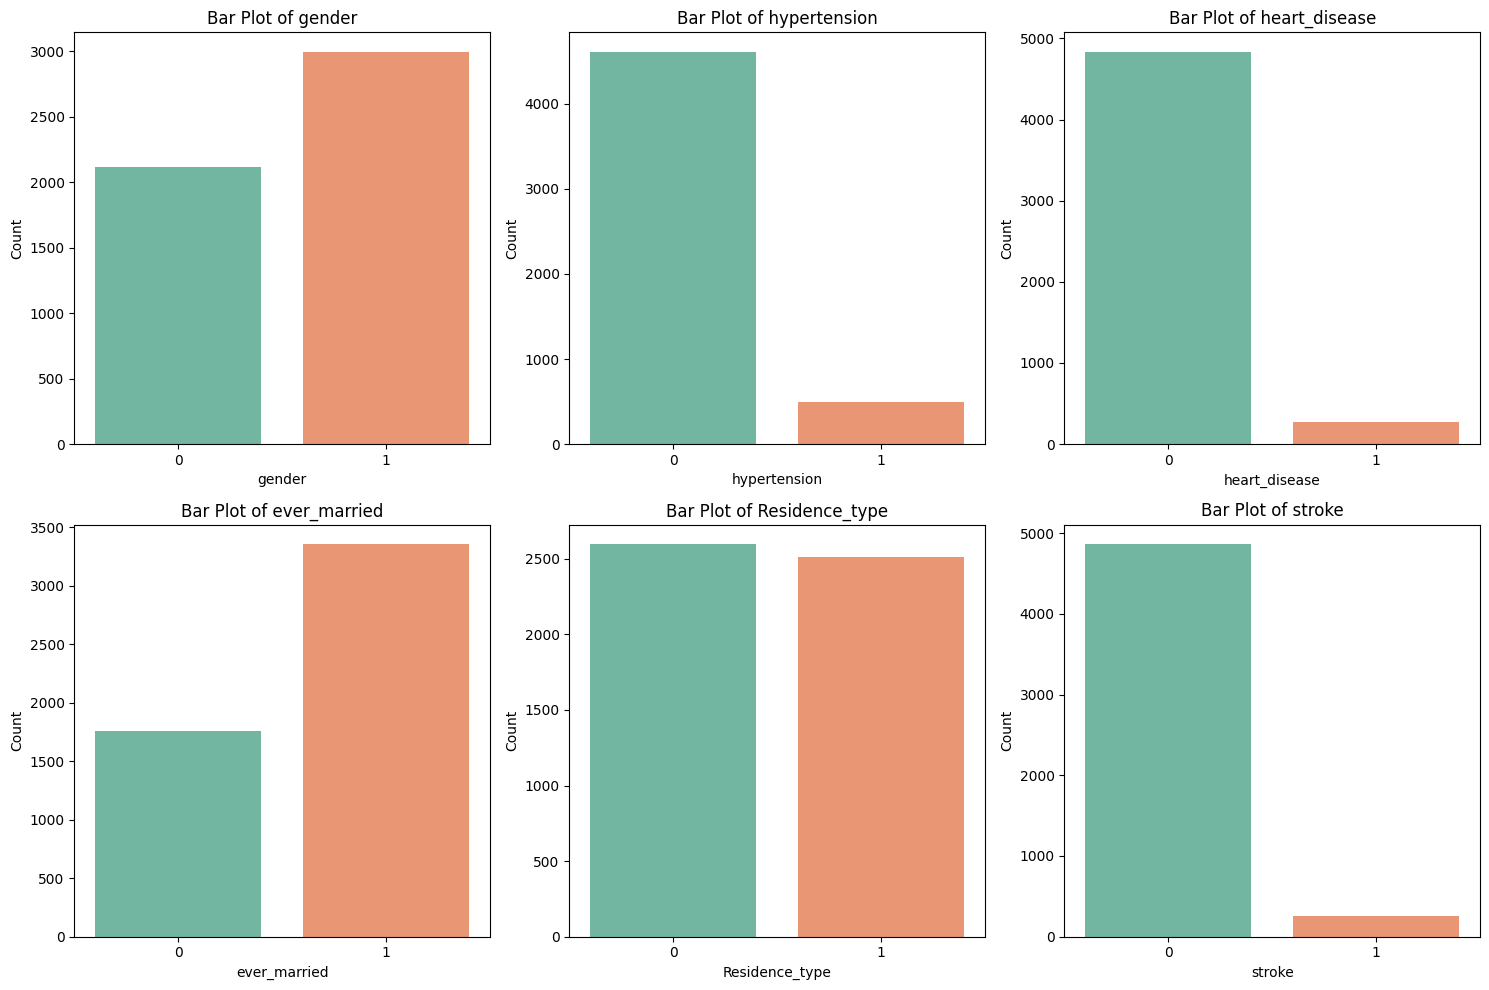

In [78]:
plot_barplot(df, filtered_classification["binary"])

In [79]:
# At Risk (Binary)
# Check for class imbalance
df['stroke'].value_counts()/len(df)

stroke
0    0.951262
1    0.048738
Name: count, dtype: float64

In [80]:
# sns.countplot(x='stroke',data=df)
# plt.show()

# 5. Outlier Detection

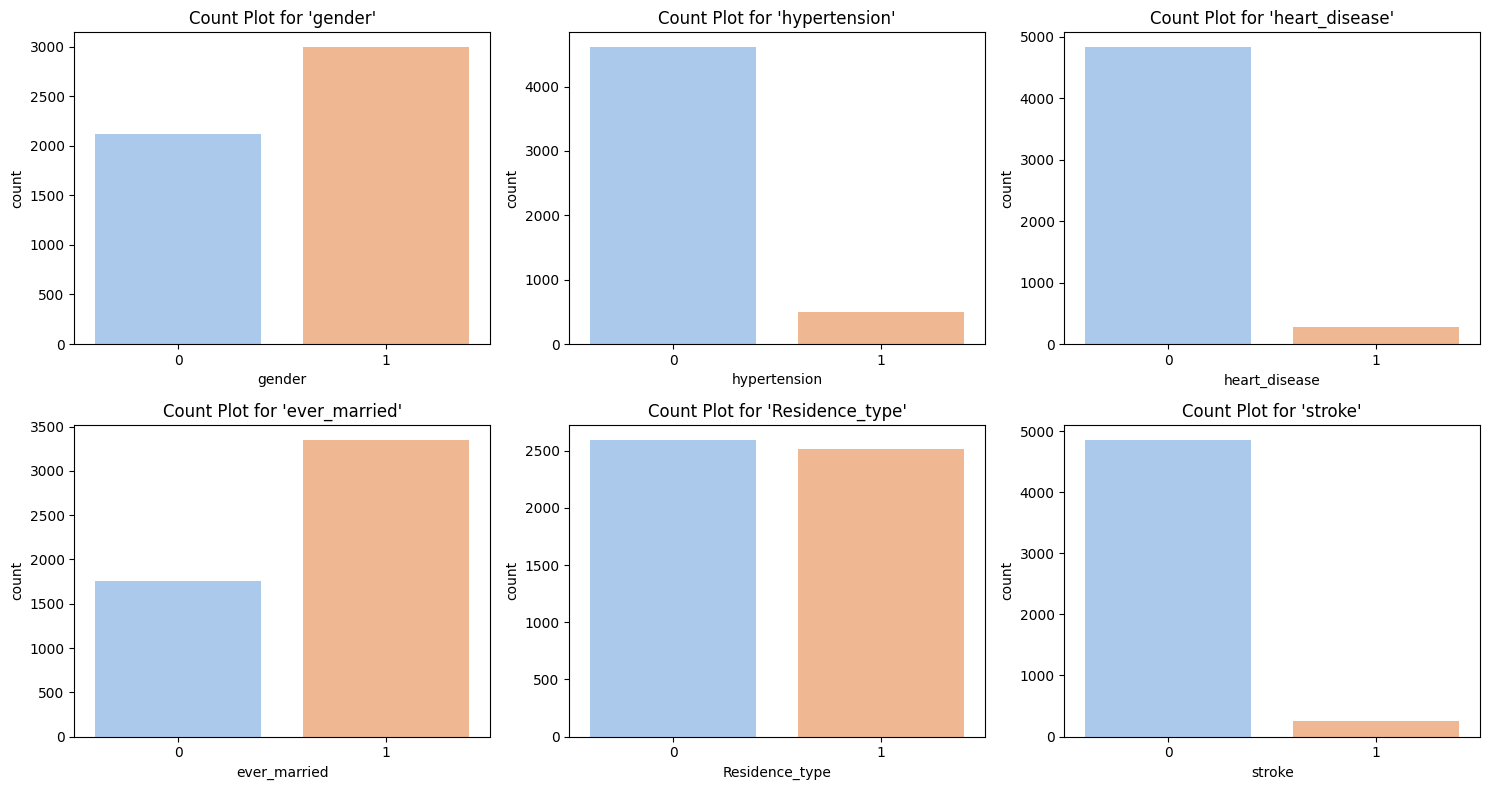

In [81]:


# Select binary columns (only those with 2 unique values: 0 and 1)
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and df[col].dtype in ['int64', 'float64']]

# Plot count plots for each binary feature
num_plots = len(binary_cols)
num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 4))
axes = axes.flatten()

for i, col in enumerate(binary_cols):
    sns.countplot(x=col, data=df, ax=axes[i], palette='pastel')
    axes[i].set_title(f"Count Plot for '{col}'")
    axes[i].set_xticks([0, 1])
    
# Hide unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [82]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distributions."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for j in range(num_plots, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


In [83]:
# plot_binary_countplots(df, filtered_classification["binary"])


In [84]:
def plot_boxplots(df, numerical_cols):
    """Plot box plots for numerical features to visualize outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], ax=axes[i], color='lightcoral')
        axes[i].set_title(f"Boxplot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [85]:
def plot_violinplots(df, numerical_cols):
    """Plot violin plots for numerical features to visualize distribution and outliers."""
    num_plots = len(numerical_cols)
    cols_per_row = 3 
    rows = (num_plots // cols_per_row) + (num_plots % cols_per_row > 0)  

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 5 * rows))
    axes = axes.flatten() 

    for i, col in enumerate(numerical_cols):
        sns.violinplot(x=df[col], ax=axes[i], color='teal')
        axes[i].set_title(f"Violin Plot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [86]:
# plot_boxplots(df, filtered_classification["numerical"])

In [87]:
# plot_violinplots(df, filtered_classification["numerical"])

In [88]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]
    
        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean

In [89]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from non-binary numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue
        
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean


In [90]:
from scipy.stats.mstats import winsorize
import numpy as np

def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in non-binary numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()
    
    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue
        
        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])
        
        print(f"🔹 Outliers in '{col}' transformed using {method} method.")
    
    return df_transformed


In [91]:
# Filter out binary columns from the list before passing to transform_outliers
transform_required_columns = ["stroke"]

# Keep only non-binary numeric columns
valid_transform_columns = [col for col in transform_required_columns 
                           if df[col].nunique() > 2 or not set(df[col].dropna().unique()).issubset({0, 1})]

# Apply transformation only if there's a valid column
if valid_transform_columns:
    df = transform_outliers(df, valid_transform_columns)
else:
    print("⚠️ No valid non-binary columns to transform.")


⚠️ No valid non-binary columns to transform.


In [92]:
# plot_boxplots(df, filtered_classification["numerical"])

# **6. Correlation Analysis** 

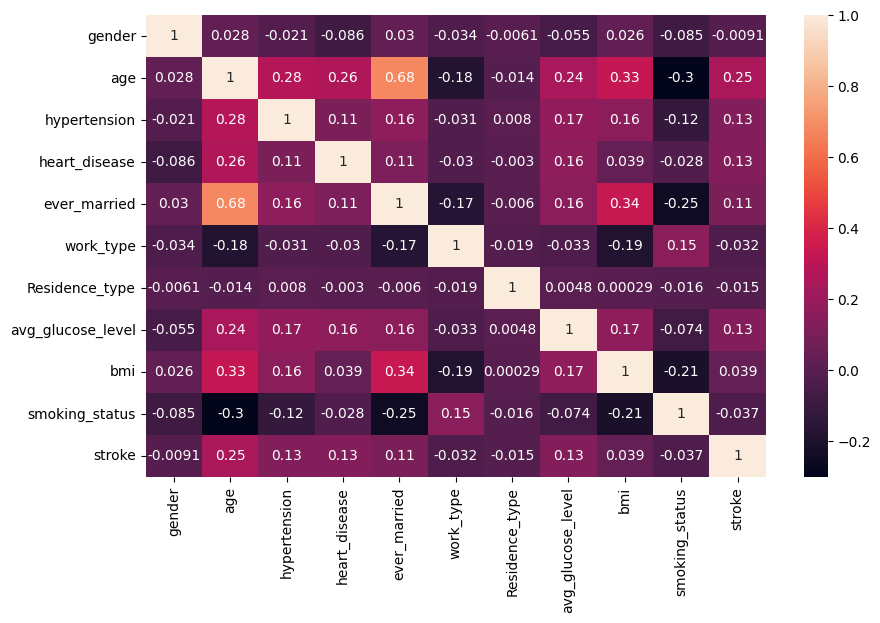

In [93]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [94]:
# def plot_correlation_heatmap(df, binary_cols):
#     """Plot a heatmap to visualize the correlation between numerical features."""
#     plt.figure(figsize=(12, 6))
#     correlation_matrix = df[numerical_cols].corr() 
#     sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
#     plt.title("🔹 Correlation Heatmap")
#     plt.show()

In [95]:
# def plot_pairplot(df, binary_cols):
#     """Plot pairplot for numerical columns to observe feature relationships."""
#     sns.pairplot(df[binary_cols], diag_kind="kde", corner=True)  
#     plt.show()

In [96]:
# plot_pairplot(df, filtered_classification["binary"])

# 7. Train-Test Split & Sampling Strategy

In [121]:
X = df.drop('stroke',axis=1)
y = df.stroke
X.shape,y.shape

((5109, 10), (5109,))

In [98]:
y.value_counts()

stroke
0    4860
1     249
Name: count, dtype: int64

([<matplotlib.patches.Wedge at 0x7c92d5c01b50>,
 [Text(-1.3836214247114578, 0.21352225429550808, 'No Stroke'),
  Text(1.1859612190393143, -0.18301908899014838, 'Stroke')],
 [Text(-0.8894709158859372, 0.13726430633282663, '95.1%'),
  Text(0.6918107111062667, -0.10676113524425322, '4.9%')])

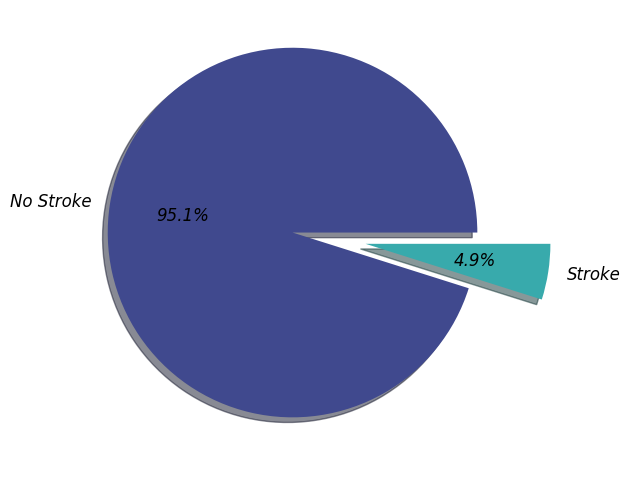

In [99]:
plt.figure(figsize=(10,6))
plt.pie(df.stroke.value_counts(),labels=['No Stroke','Stroke'],autopct='%1.1f%%',
        colors=sns.color_palette('mako',2),explode=(0.3,0.1),shadow=True,textprops={'fontsize':12,'style':'italic'})


# Balancing the target


I will use three techniques:

SMOTE
RandomOverSampler
RandomUnderSampler
✨SMOTE (Synthetic Minority Oversampling Technique): Creates synthetic data points for the minority class based on existing data points in that class. This helps increase the representation of the minority class in the training data.

✨RandomOverSampler: Randomly duplicates data points from the minority class to increase its representation. Unlike SMOTE, it doesn't create synthetic data.

✨RandomUnderSampler: Randomly removes data points from the majority class to reduce its size and match the minority class. This approach can be faster than oversampling techniques.

In [100]:
# pip show scikit-learn
# !pip install -U imbalanced-learn==0.10.1

In [101]:
# !pip show scikit-learn
# !pip show imbalanced-learn
# !pip uninstall -y scikit-learn imbalanced-learn
# !pip uninstall -y imbalanced-learn
# !pip install -U scikit-learn mlxtend

In [102]:
# !pip install imbalanced-learn==0.10.1 --quiet

In [103]:
# !pip uninstall -y scikit-learn imbalanced-learn numpy

In [104]:
!pip uninstall scikit-learn imbalanced-learn -y

Found existing installation: scikit-learn 1.2.2
Uninstalling scikit-learn-1.2.2:
  Successfully uninstalled scikit-learn-1.2.2
Found existing installation: imbalanced-learn 0.13.0
Uninstalling imbalanced-learn-0.13.0:
  Successfully uninstalled imbalanced-learn-0.13.0


In [105]:
# !pip install numpy==1.26.4 scikit-learn==1.3.2 imbalanced-learn==0.11.0
!pip install scikit-learn==1.2.2 imbalanced-learn==0.10.1 numpy==1.23.5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 66.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.0/226.0 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 91.8 MB/s eta 0:00:00:00:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.8.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.3 which is incompatible.
mkl-umath 0.1.1 requires numpy<1.27.0,>=1.26.4, but you have numpy 1.23.5 which is incompatible.
mkl-random 1.2.4 requires numpy<1.27.0,>=1.26.4, but you have numpy 1.23.5 which is incompatible.
mkl-fft 1.3.8 requires numpy<1.27

In [122]:
from imblearn.over_sampling import SMOTE,RandomOverSampler
# from imblearn.under_sampling import RandomUnderSampler
# smote = SMOTE()
# X_resampled, y_resampled = smote.fit_resample(X, y)
ros = RandomOverSampler(sampling_strategy='minority')
X_over_resampled, y_over_resampled = ros.fit_resample(X, y)
# rus = RandomUnderSampler(sampling_strategy='majority')
# X_under_resampled, y_under_resampled = rus.fit_resample(X, y)


In [123]:
# print(X_resampled.shape,y_resampled.shape)
# print(X_under_resampled.shape,y_under_resampled.shape)
print(X_over_resampled.shape,y_over_resampled.shape)

(9720, 10) (9720,)


In [108]:
# print(y_resampled.value_counts())
# print(y_under_resampled.value_counts())
print(y_over_resampled.value_counts())

stroke
1    4860
0    4860
Name: count, dtype: int64


RandomOverampler

In [109]:
pip install xgboost lightgbm catboost imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [112]:
feature_names = X.columns.tolist()
feature_names
# run_xai_pipeline(X, y, feature_names)

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status']

In [118]:
pip install shap lime xgboost imbalanced-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [125]:
import shap
from lime import lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score

# 1. Data Preparation
def prepare_data(X, y):
    """Handle data balancing and splitting"""
    # Apply RandomOverSampler
    ros = RandomOverSampler(random_state=42)
    X_resampled, y_resampled = ros.fit_resample(X, y)
    
    # Split into train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X_resampled, y_resampled,
        test_size=0.3,
        random_state=42,
        stratify=y_resampled
    )
    return X_train, X_test, y_train, y_test

# 2. Model Training
def train_models(X_train, y_train):
    """Train and return the top models"""
    models = {
        'ExtraTrees': ExtraTreesClassifier(n_estimators=100, random_state=42),
        'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42),
        'GradientBoost': XGBClassifier(random_state=42, eval_metric='logloss')
    }
    
    for name, model in models.items():
        model.fit(X_train, y_train)
        if name == 'GradientBoost':
            model.get_booster().feature_names = X_train.columns.tolist()
        train_acc = accuracy_score(y_train, model.predict(X_train))
        print(f"{name} trained - Training accuracy: {train_acc:.4f}")
    
    return models

# 3. SHAP Analysis
def run_shap_analysis(models, X_test):
    """Perform SHAP analysis on all models"""
    for name, model in models.items():
        print(f"\nRunning SHAP for {name}...")
        try:
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_test[:100])
            
            plt.figure(figsize=(10, 6))
            if isinstance(shap_values, list):
                shap.summary_plot(shap_values[1], X_test[:100], show=False)
            else:
                shap.summary_plot(shap_values, X_test[:100], show=False)
            plt.title(f'SHAP Summary - {name}')
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"SHAP error for {name}: {str(e)}")


In [126]:
# 4. LIME Analysis
def run_lime_analysis(models, X_train, X_test, y_test):
    """Perform LIME analysis on all models"""
    explainer = lime_tabular.LimeTabularExplainer(
        training_data=np.array(X_train),
        feature_names=X_train.columns.tolist(),
        class_names=['No Stroke', 'Stroke'],
        mode='classification',
        verbose=False,
        random_state=42
    )
    
    for name, model in models.items():
        print(f"\nRunning LIME for {name}...")
        try:
            # Find stroke cases (y_test == 1)
            stroke_idx = np.where(y_test == 1)[0]
            idx = np.random.choice(stroke_idx) if len(stroke_idx) > 0 else 0
            
            predict_fn = lambda x: model.predict_proba(x)
            exp = explainer.explain_instance(
                X_test.iloc[idx].values,
                predict_fn,
                num_features=10,
                top_labels=1
            )
            
            fig = exp.as_pyplot_figure(label=1)
            plt.title(f'LIME Explanation - {name}\n(Actual: {"Stroke" if y_test.iloc[idx] else "No Stroke"})')
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"LIME error for {name}: {str(e)}")


Preparing data...

Training models...
ExtraTrees trained - Training accuracy: 1.0000
RandomForest trained - Training accuracy: 1.0000
GradientBoost trained - Training accuracy: 0.9972

Running SHAP analysis...

Running SHAP for ExtraTrees...


The figure layout has changed to tight


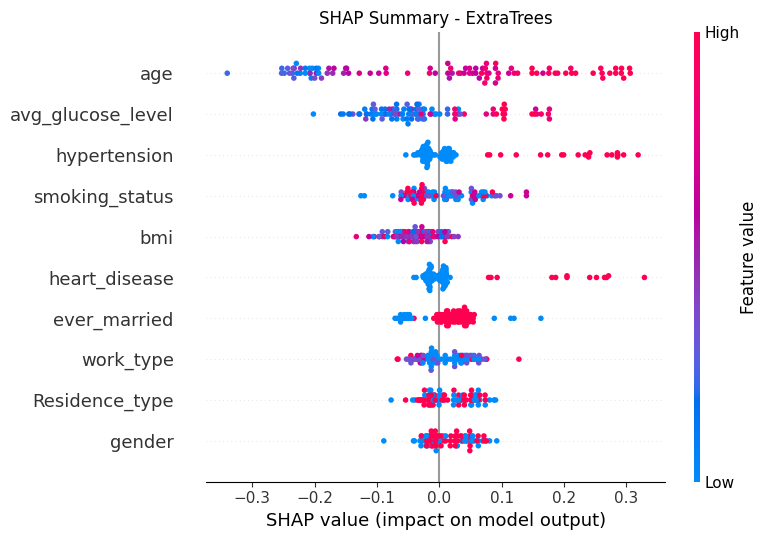


Running SHAP for RandomForest...


The figure layout has changed to tight


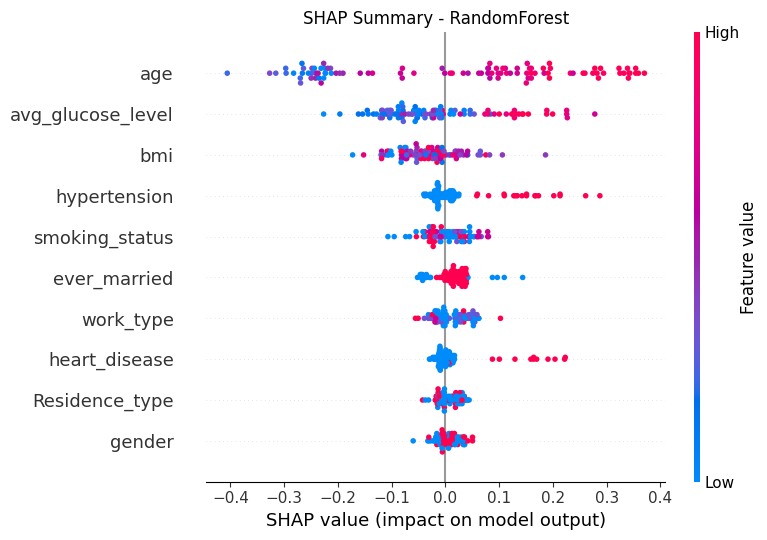


Running SHAP for GradientBoost...


The figure layout has changed to tight


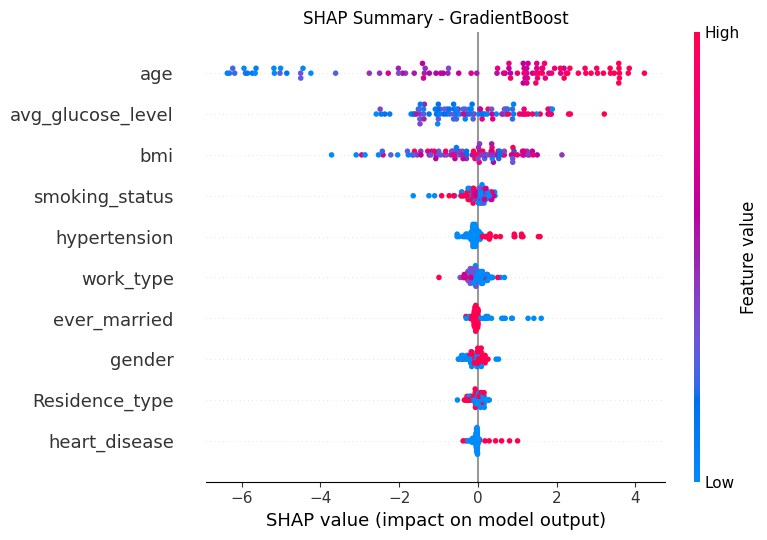


Running LIME analysis...

Running LIME for ExtraTrees...


X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names


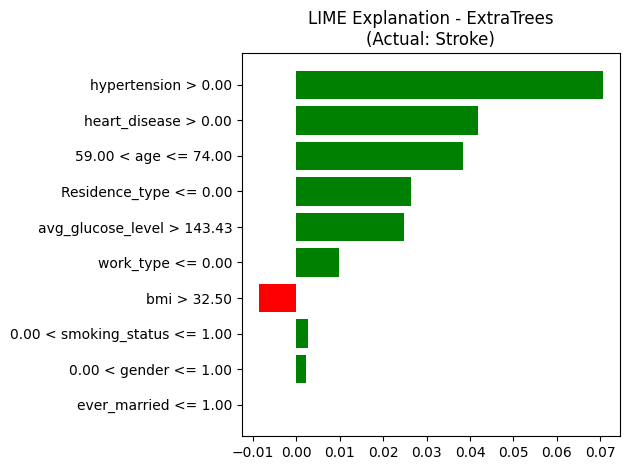


Running LIME for RandomForest...


X does not have valid feature names, but RandomForestClassifier was fitted with feature names


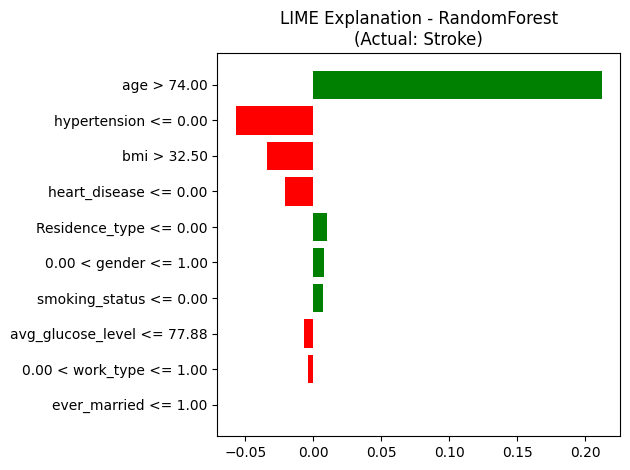


Running LIME for GradientBoost...


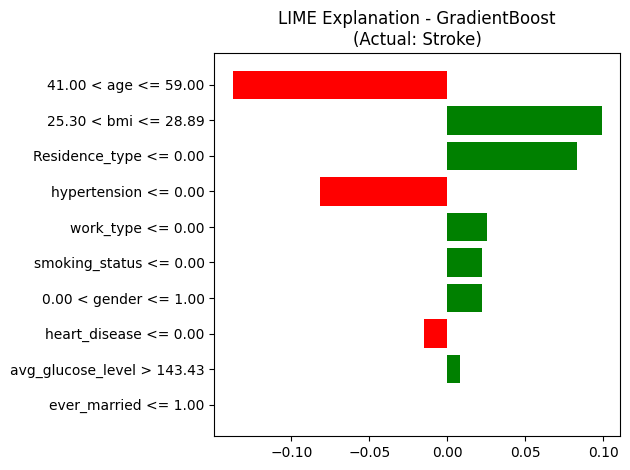

In [127]:
# Main Pipeline
def explain_stroke_models(X, y):
    """Complete XAI pipeline for stroke prediction"""
    # 1. Prepare data
    print("Preparing data...")
    X_train, X_test, y_train, y_test = prepare_data(X, y)
    
    # 2. Train models
    print("\nTraining models...")
    models = train_models(X_train, y_train)
    
    # 3. SHAP analysis
    print("\nRunning SHAP analysis...")
    run_shap_analysis(models, X_test)
    
    # 4. LIME analysis
    print("\nRunning LIME analysis...")
    run_lime_analysis(models, X_train, X_test, y_test)

# Run the analysis
if __name__ == "__main__":
    # Assuming you have:
    # X = df.drop('stroke', axis=1)
    # y = df['stroke']
    
    explain_stroke_models(X, y)

In [124]:
# feature_names = X.columns.tolist()
# run_xai_pipeline(X, y, feature_names)